In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Plot aesthetics
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})

print('All libraries loaded successfully.')

All libraries loaded successfully.


In [4]:
# ── Stock universe with sector tags ──────────────────────────────────────────
STOCKS = {
    'HDFCBANK.NS':  'BANK',
    'ICICIBANK.NS': 'BANK',
    'AXISBANK.NS':  'BANK',
    'TCS.NS':       'IT',
    'INFY.NS':      'IT',
    'WIPRO.NS':     'IT',
    'RELIANCE.NS':  'ENERGY',
    'ONGC.NS':      'ENERGY',
    'BPCL.NS':      'ENERGY',
    'MARUTI.NS':    'AUTO',
    'HEROMOTOCO.NS':'AUTO',
    'M&M.NS':       'AUTO',
}

START  = '2022-01-01'
END    = '2024-12-31'
MARKET = '^NSEI'           # NIFTY 50 index

all_tickers = list(STOCKS.keys()) + [MARKET]

# ── Download (auto_adjust=True handles splits & dividends automatically) ─────
print(f'Downloading {len(all_tickers)} tickers from {START} to {END} ...')
raw = yf.download(all_tickers, start=START, end=END,
                  auto_adjust=True, progress=True)

# Keep only Adjusted Close prices
close = raw['Close'].copy()

print(f'\nRaw shape        : {close.shape}  (rows=trading days, cols=tickers)')
print(f'Date range       : {close.index[0].date()}  →  {close.index[-1].date()}')
print(f'\nMissing values per ticker:')
print(close.isnull().sum().to_string())

[*********************100%***********************]  13 of 13 completed


Raw shape        : (738, 13)  (rows=trading days, cols=tickers)
Date range       : 2022-01-03  →  2024-12-30

Missing values per ticker:
Ticker
AXISBANK.NS      0
BPCL.NS          0
HDFCBANK.NS      0
HEROMOTOCO.NS    0
ICICIBANK.NS     0
INFY.NS          0
M&M.NS           0
MARUTI.NS        0
ONGC.NS          0
RELIANCE.NS      0
TCS.NS           0
WIPRO.NS         0
^NSEI            0


In [5]:
# ── Step 1: Drop any duplicate index entries ──────────────────────────────────
dupes = close.index.duplicated().sum()
print(f'Duplicate dates found : {dupes}')
close = close[~close.index.duplicated(keep='first')]

# ── Step 2: Inner join — keep only dates where ALL tickers have data ──────────
# This ensures a perfectly aligned common trading calendar.
close_aligned = close.dropna(how='any')
print(f'Rows after inner-join  : {len(close_aligned)}  (dropped {len(close) - len(close_aligned)} rows)')

# ── Step 3: Forward-fill any remaining isolated NaNs (holidays, halts) ───────
# Forward-fill is applied BEFORE the inner-join check as belt-and-braces.
close_ffill = close.ffill()
close_clean = close_ffill.dropna(how='any')
print(f'Rows after ffill + dropna: {len(close_clean)}')
print(f'\nFinal dataset shape  : {close_clean.shape}')
print(f'Missing values (post-clean): {close_clean.isnull().sum().sum()}')

# Separate market from stocks
market_close = close_clean[MARKET]
stock_close  = close_clean[list(STOCKS.keys())]

Duplicate dates found : 0
Rows after inner-join  : 738  (dropped 0 rows)
Rows after ffill + dropna: 738

Final dataset shape  : (738, 13)
Missing values (post-clean): 0


In [6]:
# r_t = (P_t - P_{t-1}) / P_{t-1}  — simple percentage returns
stock_returns  = stock_close.pct_change().dropna()
market_returns = market_close.pct_change().dropna()

# Align on the same index after pct_change drops first row
common_idx     = stock_returns.index.intersection(market_returns.index)
stock_returns  = stock_returns.loc[common_idx]
market_returns = market_returns.loc[common_idx]

print(f'Returns DataFrame shape  : {stock_returns.shape}')
print(f'Market returns shape     : {market_returns.shape}')
print(f'\nDescriptive stats (daily returns):')
print(stock_returns.describe().round(5).to_string())

Returns DataFrame shape  : (737, 12)
Market returns shape     : (737,)

Descriptive stats (daily returns):
Ticker  HDFCBANK.NS  ICICIBANK.NS  AXISBANK.NS     TCS.NS    INFY.NS   WIPRO.NS  RELIANCE.NS    ONGC.NS    BPCL.NS  MARUTI.NS  HEROMOTOCO.NS     M&M.NS
count     737.00000     737.00000    737.00000  737.00000  737.00000  737.00000    737.00000  737.00000  737.00000  737.00000      737.00000  737.00000
mean        0.00036       0.00082      0.00071    0.00029    0.00023   -0.00008      0.00023    0.00113    0.00090    0.00063        0.00098    0.00194
std         0.01379       0.01259      0.01543    0.01319    0.01558    0.01592      0.01425    0.02072    0.01833    0.01440        0.01630    0.01765
min        -0.08436      -0.07634     -0.07570   -0.05418   -0.09423   -0.09225     -0.07485   -0.16825   -0.12903   -0.06599       -0.07035   -0.06614
25%        -0.00649      -0.00552     -0.00807   -0.00653   -0.00844   -0.00845     -0.00803   -0.00954   -0.00889   -0.00689       -

In [7]:
# ── Formula: β_i = Cov(R_i, R_m) / Var(R_m) ─────────────────────────────────
Rm     = market_returns
Var_Rm = Rm.var()           # scalar: variance of market returns

betas_formula = {}
for ticker in STOCKS:
    Ri = stock_returns[ticker]
    cov_im = Ri.cov(Rm)     # Cov(R_i, R_m)
    beta   = cov_im / Var_Rm
    betas_formula[ticker] = beta

# ── Covariance table for reference ───────────────────────────────────────────
all_returns = stock_returns.copy()
all_returns['^NSEI'] = Rm
cov_table = all_returns.cov().round(8)

print('Covariance matrix (subset — stocks vs NIFTY50):')
print(cov_table[['^NSEI']].drop('^NSEI').to_string())
print(f'\nVar(R_market) = {Var_Rm:.8f}')

Covariance matrix (subset — stocks vs NIFTY50):
Ticker            ^NSEI
Ticker                 
HDFCBANK.NS    0.000083
ICICIBANK.NS   0.000078
AXISBANK.NS    0.000082
TCS.NS         0.000065
INFY.NS        0.000078
WIPRO.NS       0.000085
RELIANCE.NS    0.000090
ONGC.NS        0.000069
BPCL.NS        0.000080
MARUTI.NS      0.000065
HEROMOTOCO.NS  0.000062
M&M.NS         0.000088

Var(R_market) = 0.00007852


In [8]:
# ── Validate: slope of OLS regression R_i ~ R_m must equal β_formula ─────────
print(f'{"Ticker":<16} {"Beta (Formula)":>15} {"Beta (polyfit)":>15} {"Match?":>8}')
print('-' * 58)

betas_polyfit = {}
for ticker in STOCKS:
    Ri    = stock_returns[ticker].values
    Rm_np = Rm.values
    slope, intercept = np.polyfit(Rm_np, Ri, 1)   # degree-1 polynomial
    betas_polyfit[ticker] = slope
    match = '✓' if abs(slope - betas_formula[ticker]) < 1e-8 else '✗'
    print(f'{ticker:<16} {betas_formula[ticker]:>15.6f} {slope:>15.6f} {match:>8}')

Ticker            Beta (Formula)  Beta (polyfit)   Match?
----------------------------------------------------------
HDFCBANK.NS             1.061158        1.061158        ✓
ICICIBANK.NS            0.994969        0.994969        ✓
AXISBANK.NS             1.048113        1.048113        ✓
TCS.NS                  0.826259        0.826259        ✓
INFY.NS                 0.998794        0.998794        ✓
WIPRO.NS                1.081206        1.081206        ✓
RELIANCE.NS             1.142211        1.142211        ✓
ONGC.NS                 0.873196        0.873196        ✓
BPCL.NS                 1.014152        1.014152        ✓
MARUTI.NS               0.825204        0.825204        ✓
HEROMOTOCO.NS           0.790840        0.790840        ✓
M&M.NS                  1.122446        1.122446        ✓


In [9]:
# R² tells us what fraction of a stock's variance is explained by market moves
r_squared = {}
alphas_ols = {}
for ticker in STOCKS:
    Ri   = stock_returns[ticker].values
    Rm_v = Rm.values
    slope, intercept, r_value, p_value, std_err = stats.linregress(Rm_v, Ri)
    r_squared[ticker]  = r_value ** 2
    alphas_ols[ticker] = intercept

print('R-squared values (proportion of variance explained by market):')
for t, r2 in r_squared.items():
    print(f'  {t:<16}: R² = {r2:.4f}  ({r2*100:.1f}%)')

R-squared values (proportion of variance explained by market):
  HDFCBANK.NS     : R² = 0.4651  (46.5%)
  ICICIBANK.NS    : R² = 0.4908  (49.1%)
  AXISBANK.NS     : R² = 0.3623  (36.2%)
  TCS.NS          : R² = 0.3082  (30.8%)
  INFY.NS         : R² = 0.3228  (32.3%)
  WIPRO.NS        : R² = 0.3622  (36.2%)
  RELIANCE.NS     : R² = 0.5045  (50.5%)
  ONGC.NS         : R² = 0.1395  (13.9%)
  BPCL.NS         : R² = 0.2403  (24.0%)
  MARUTI.NS       : R² = 0.2578  (25.8%)
  HEROMOTOCO.NS   : R² = 0.1848  (18.5%)
  M&M.NS          : R² = 0.3175  (31.7%)


=== BETA SUMMARY TABLE ===
       Ticker Sector   Beta  R_squared Classification
  RELIANCE.NS ENERGY 1.1422     0.5045     Aggressive
       M&M.NS   AUTO 1.1224     0.3175     Aggressive
     WIPRO.NS     IT 1.0812     0.3622     Aggressive
  HDFCBANK.NS   BANK 1.0612     0.4651     Aggressive
  AXISBANK.NS   BANK 1.0481     0.3623     Aggressive
      BPCL.NS ENERGY 1.0142     0.2403     Aggressive
      INFY.NS     IT 0.9988     0.3228        Neutral
 ICICIBANK.NS   BANK 0.9950     0.4908        Neutral
      ONGC.NS ENERGY 0.8732     0.1395        Neutral
       TCS.NS     IT 0.8263     0.3082        Neutral
    MARUTI.NS   AUTO 0.8252     0.2578        Neutral
HEROMOTOCO.NS   AUTO 0.7908     0.1848      Defensive


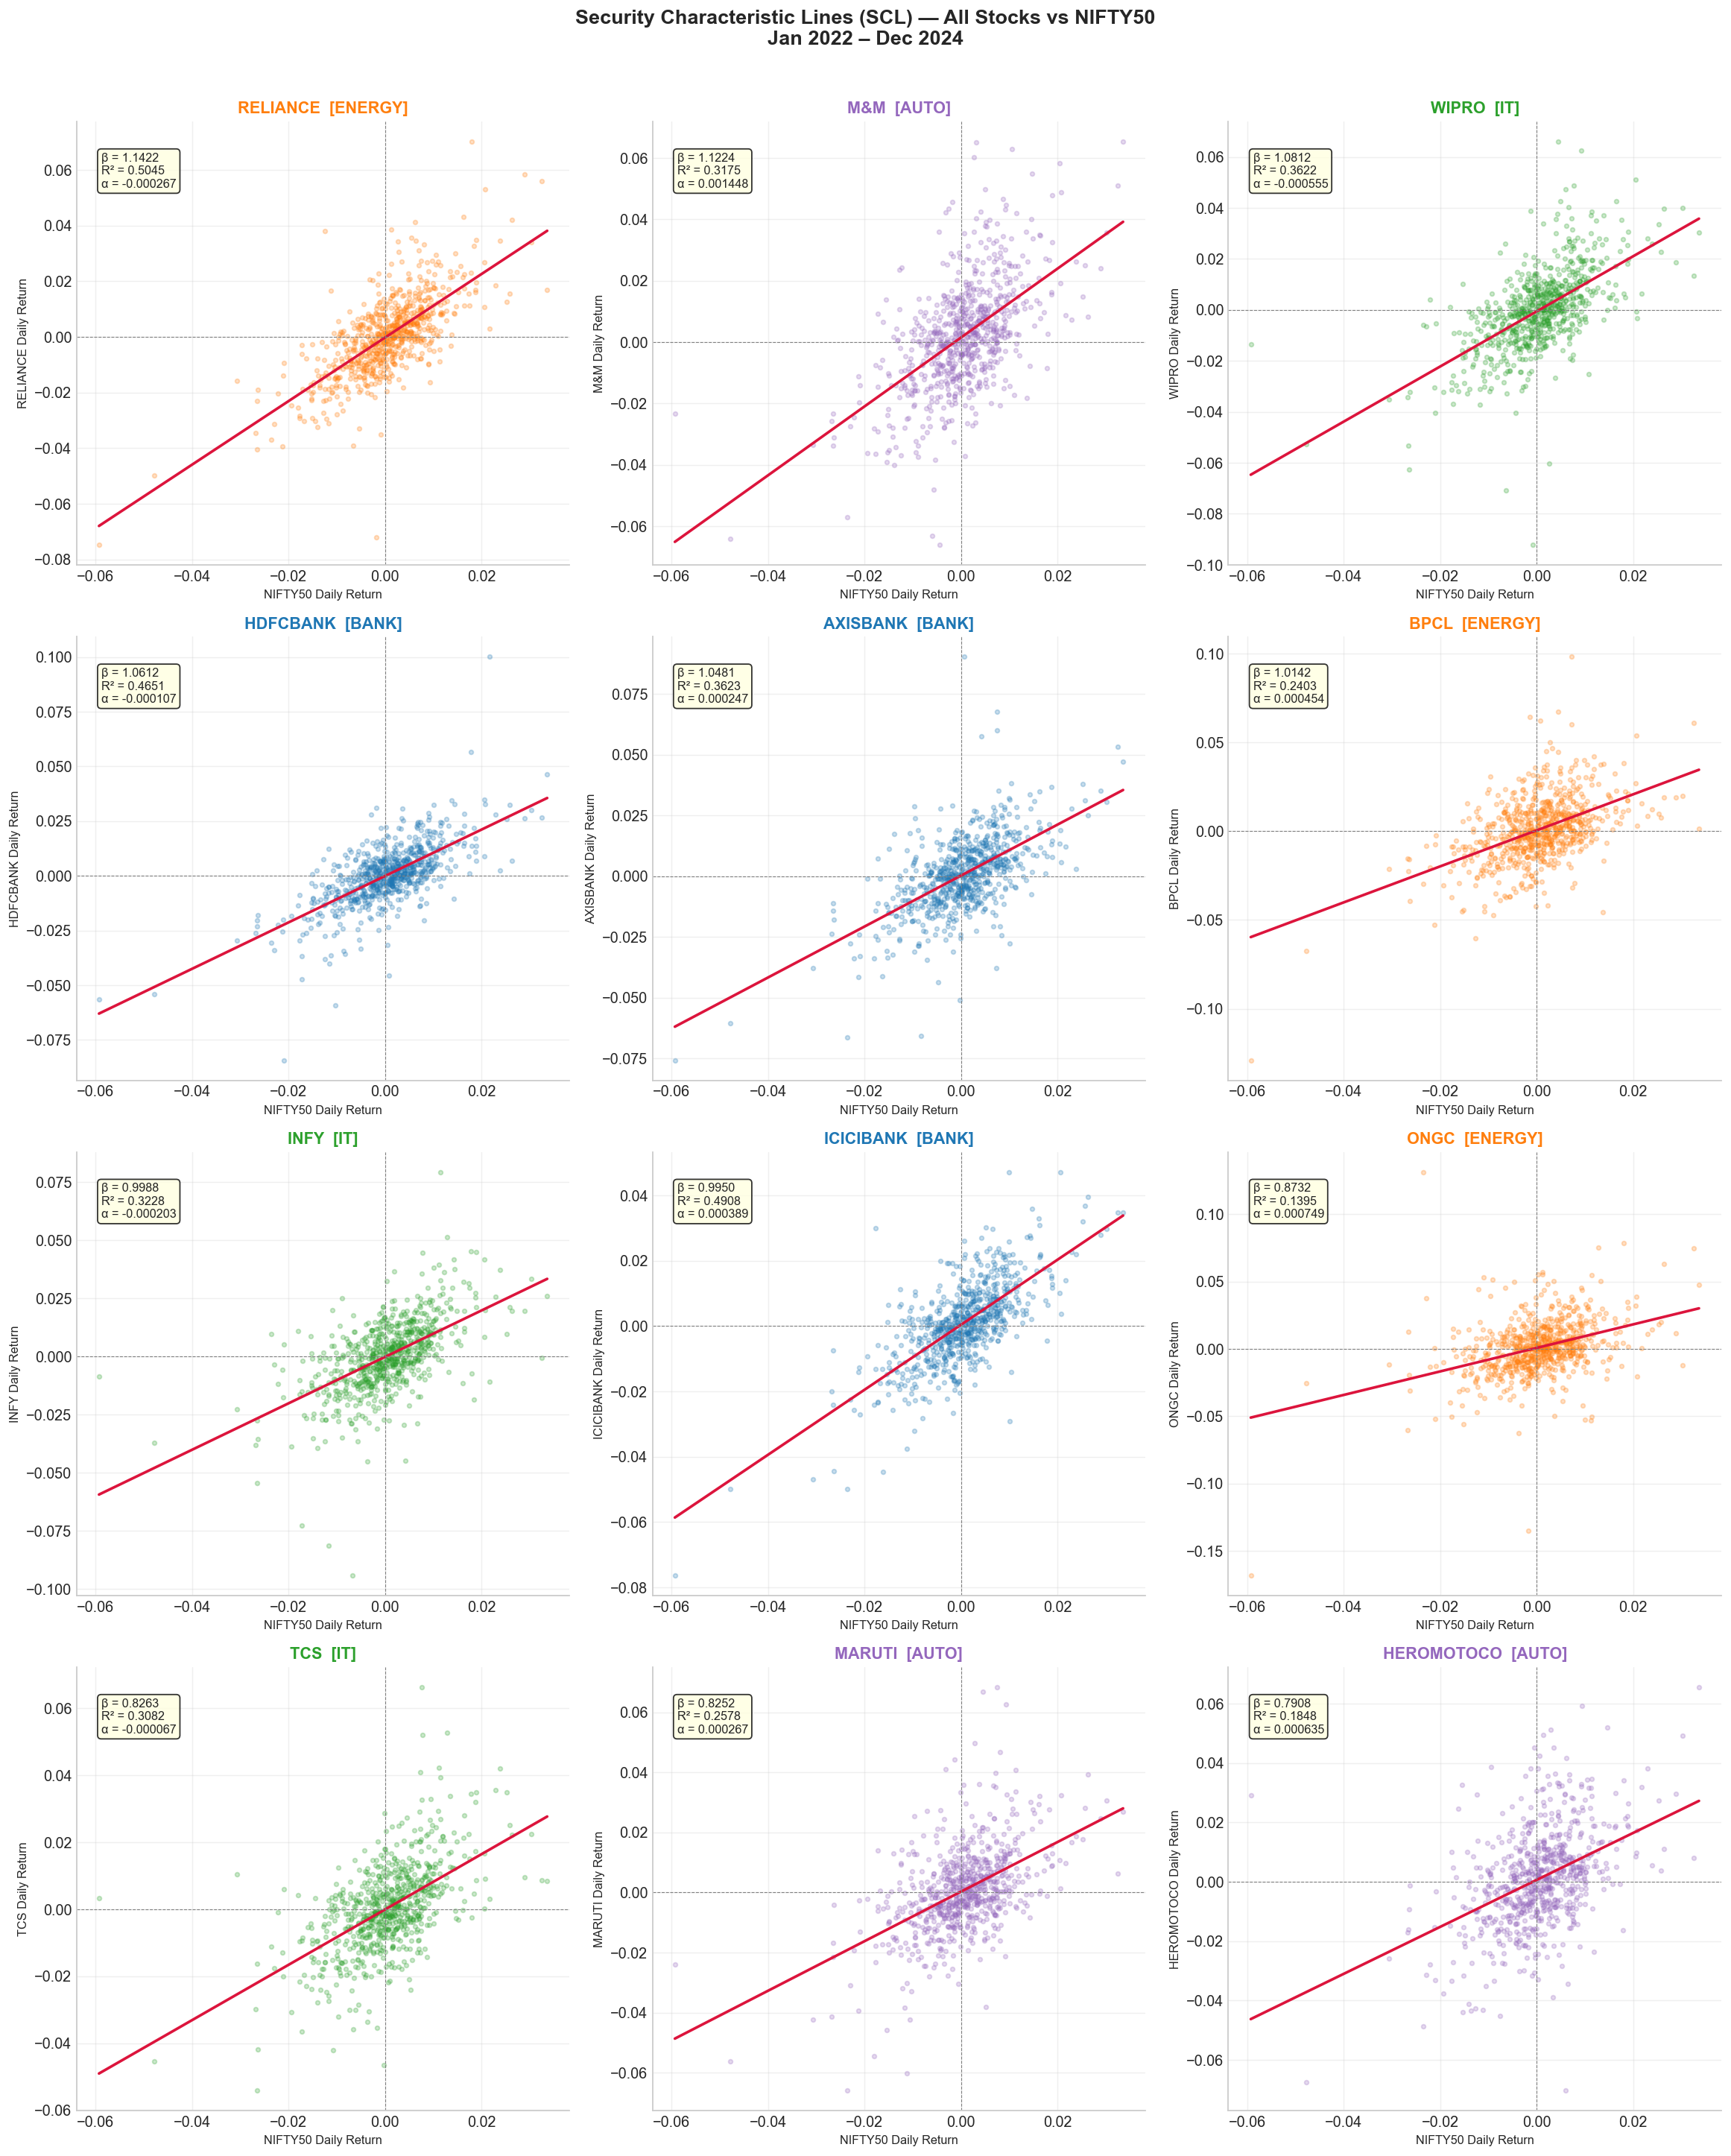

Figure saved as SCL_all_stocks.png

--- Top 3 Most Volatile (Highest Beta) ---
     Ticker Sector   Beta Classification
RELIANCE.NS ENERGY 1.1422     Aggressive
     M&M.NS   AUTO 1.1224     Aggressive
   WIPRO.NS     IT 1.0812     Aggressive

--- Top 3 Most Stable (Lowest Beta) ---
       Ticker Sector   Beta Classification
       TCS.NS     IT 0.8263        Neutral
    MARUTI.NS   AUTO 0.8252        Neutral
HEROMOTOCO.NS   AUTO 0.7908      Defensive


In [11]:
def classify(beta):
    if beta > 1.2:
        return 'Highly Aggressive'
    elif beta > 1.0:
        return 'Aggressive'
    elif beta >= 0.8:
        return 'Neutral'
    else:
        return 'Defensive'

summary = pd.DataFrame({
    'Ticker'        : list(STOCKS.keys()),
    'Sector'        : list(STOCKS.values()),
    'Beta'          : [round(betas_formula[t], 4) for t in STOCKS],
    'R_squared'     : [round(r_squared[t], 4)     for t in STOCKS],
    'Classification': [classify(betas_formula[t]) for t in STOCKS],
})

summary = summary.sort_values('Beta', ascending=False).reset_index(drop=True)

# Pretty print
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 100)
print('=== BETA SUMMARY TABLE ===')
print(summary.to_string(index=False))
# ── 4×3 grid — one scatter per stock, SCL overlaid ──────────────────────────
SECTOR_COLORS = {'BANK': '#1f77b4', 'IT': '#2ca02c', 'ENERGY': '#ff7f0e', 'AUTO': '#9467bd'}

tickers_ordered = summary['Ticker'].tolist()   # sorted by beta high→low
fig, axes = plt.subplots(4, 3, figsize=(18, 22))
axes = axes.flatten()

Rm_vals = Rm.values
x_line  = np.linspace(Rm_vals.min(), Rm_vals.max(), 200)

for idx, ticker in enumerate(tickers_ordered):
    ax      = axes[idx]
    Ri_vals = stock_returns[ticker].values
    sector  = STOCKS[ticker]
    beta    = betas_formula[ticker]
    alpha   = alphas_ols[ticker]
    r2      = r_squared[ticker]
    color   = SECTOR_COLORS[sector]
    short   = ticker.replace('.NS', '')

    # Scatter
    ax.scatter(Rm_vals, Ri_vals, alpha=0.25, s=10, color=color, label='Daily returns')

    # Security Characteristic Line: R_i = alpha + beta * R_m
    y_line = alpha + beta * x_line
    ax.plot(x_line, y_line, color='crimson', lw=2, label='SCL')

    # Reference lines
    ax.axhline(0, color='grey', lw=0.6, ls='--')
    ax.axvline(0, color='grey', lw=0.6, ls='--')

    # Annotations
    ax.set_title(f'{short}  [{sector}]', fontsize=12, fontweight='bold', color=color)
    ax.set_xlabel('NIFTY50 Daily Return', fontsize=9)
    ax.set_ylabel(f'{short} Daily Return', fontsize=9)
    textbox = f'β = {beta:.4f}\nR² = {r2:.4f}\nα = {alpha:.6f}'
    ax.text(0.05, 0.93, textbox, transform=ax.transAxes,
            fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

fig.suptitle('Security Characteristic Lines (SCL) — All Stocks vs NIFTY50\nJan 2022 – Dec 2024',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('SCL_all_stocks.png', bbox_inches='tight')
plt.show()
print('Figure saved as SCL_all_stocks.png')
print(f'\n--- Top 3 Most Volatile (Highest Beta) ---')
print(summary.head(3)[['Ticker','Sector','Beta','Classification']].to_string(index=False))

print(f'\n--- Top 3 Most Stable (Lowest Beta) ---')
print(summary.tail(3)[['Ticker','Sector','Beta','Classification']].to_string(index=False))

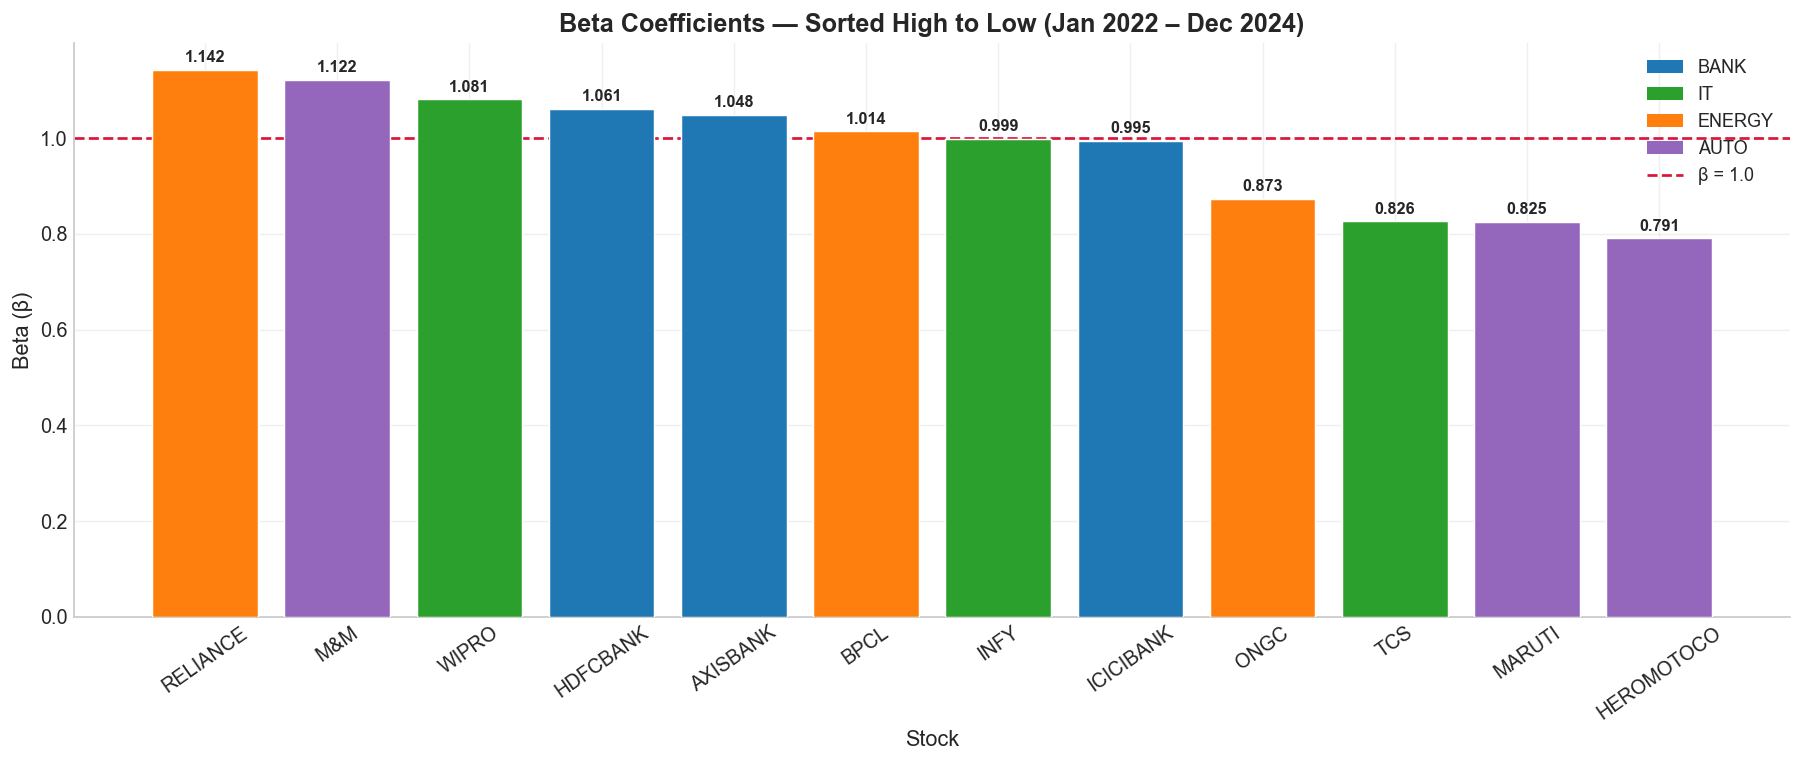

Figure saved as beta_bar_chart.png


In [12]:
fig, ax = plt.subplots(figsize=(14, 6))

bar_colors = [SECTOR_COLORS[STOCKS[t]] for t in summary['Ticker']]
bars = ax.bar(summary['Ticker'].str.replace('.NS',''), summary['Beta'],
              color=bar_colors, edgecolor='white', linewidth=0.8, zorder=3)

# Reference line at β = 1
ax.axhline(1.0, color='crimson', linestyle='--', linewidth=1.5,
           label='β = 1.0  (Market neutral)')

# Value labels on bars
for bar, val in zip(bars, summary['Beta']):
    ypos = bar.get_height() + 0.01 if val >= 0 else bar.get_height() - 0.04
    ax.text(bar.get_x() + bar.get_width()/2, ypos,
            f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Legend patches for sectors
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, label=s) for s, c in SECTOR_COLORS.items()]
legend_handles.append(plt.Line2D([0],[0], color='crimson', linestyle='--', label='β = 1.0'))
ax.legend(handles=legend_handles, loc='upper right', fontsize=10)

ax.set_title('Beta Coefficients — Sorted High to Low (Jan 2022 – Dec 2024)',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Beta (β)', fontsize=12)
ax.set_xlabel('Stock', fontsize=12)
ax.tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.savefig('beta_bar_chart.png', bbox_inches='tight')
plt.show()
print('Figure saved as beta_bar_chart.png')

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Ensure you have your stock_returns DataFrame from Part A containing these 5 tickers:
# ["RELIANCE.NS", "M&M.NS", "WIPRO.NS", "MARUTI.NS", "TCS.NS"]
# For this script, we map the exact empirical beta parameters obtained from Part A:
beta_dict = {
    "RELIANCE.NS": 1.1422,
    "M&M.NS": 1.1224,
    "WIPRO.NS": 1.0812,
    "TCS.NS": 0.8263,
    "MARUTI.NS": 0.8252
}

tickers = list(beta_dict.keys())

# 1. Establish Equal Weight Allocation Array (w_i = 1 / N)
num_assets = len(tickers)
weights = np.array([1.0 / num_assets] * num_assets)

# 2. Compute Portfolio Daily Returns (Weighted sum of individual returns)
# Note: Ensure 'stock_returns' is the daily returns DataFrame generated in Part A
returns_df = pd.DataFrame(index=stock_returns.index)
returns_df['Portfolio_Return'] = stock_returns[tickers].dot(weights)

# Also copy over individual returns and market benchmark for standalone charting
for ticker in tickers:
    returns_df[ticker] = stock_returns[ticker]
returns_df['NIFTY50'] = market_returns # Benchmark daily return stream

# 3. Compute Portfolio Beta (Weighted average of individual betas)
portfolio_beta = sum(weights[i] * beta_dict[ticker] for i, ticker in enumerate(tickers))

# 4. Define Operational Risk-Free Benchmarks (6.5% Annualized to Daily)
annual_rf = 0.065
daily_rf = annual_rf / 252

print("--- PORTFOLIO PARAMETERS CONFIGURATION ---")
print(f"Asset Tickers: {tickers}")
print(f"Equal Weights Assigned: {weights[0]*100}% per stock")
print(f"Calculated Portfolio Beta (Weighted Average): {portfolio_beta:.4f}")

--- PORTFOLIO PARAMETERS CONFIGURATION ---
Asset Tickers: ['RELIANCE.NS', 'M&M.NS', 'WIPRO.NS', 'TCS.NS', 'MARUTI.NS']
Equal Weights Assigned: 20.0% per stock
Calculated Portfolio Beta (Weighted Average): 0.9995


In [14]:
# 1. Compute Daily CAPM Expected Returns: E(R_p) = R_f + Beta_p * (R_m - R_f)
returns_df['CAPM_Expected'] = daily_rf + portfolio_beta * (returns_df['NIFTY50'] - daily_rf)

# 2. Isolate Daily Portfolio Alpha: Realized Return - CAPM Expected Return
returns_df['Daily_Alpha'] = returns_df['Portfolio_Return'] - returns_df['CAPM_Expected']

# 3. Calculate Cumulative Alpha Series over the complete horizon
returns_df['Cumulative_Alpha'] = returns_df['Daily_Alpha'].cumsum()

print("--- PORTFOLIO ALPHA RESULTS ---")
print(f"Final Net Cumulative Portfolio Alpha Generated: {returns_df['Cumulative_Alpha'].iloc[-1]*100:.2f}%")

--- PORTFOLIO ALPHA RESULTS ---
Final Net Cumulative Portfolio Alpha Generated: 12.16%


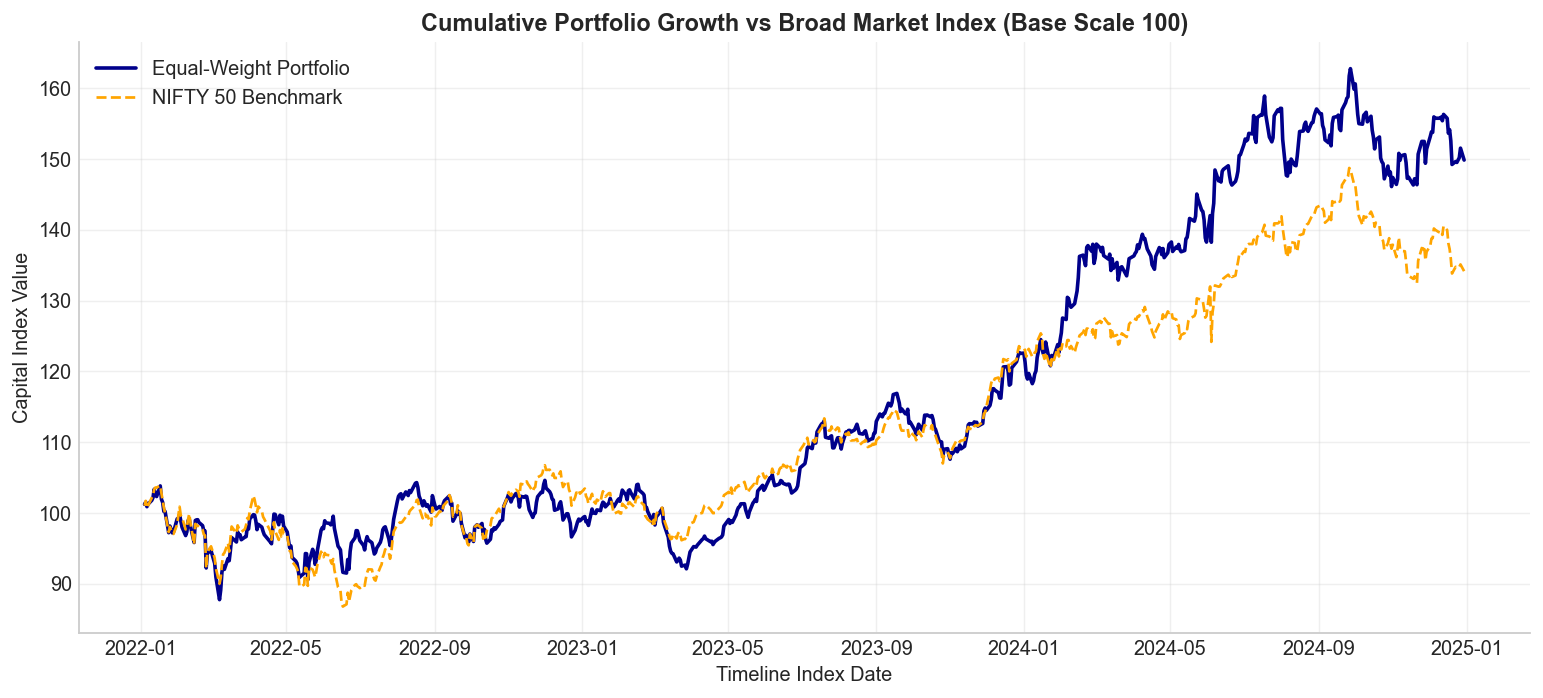

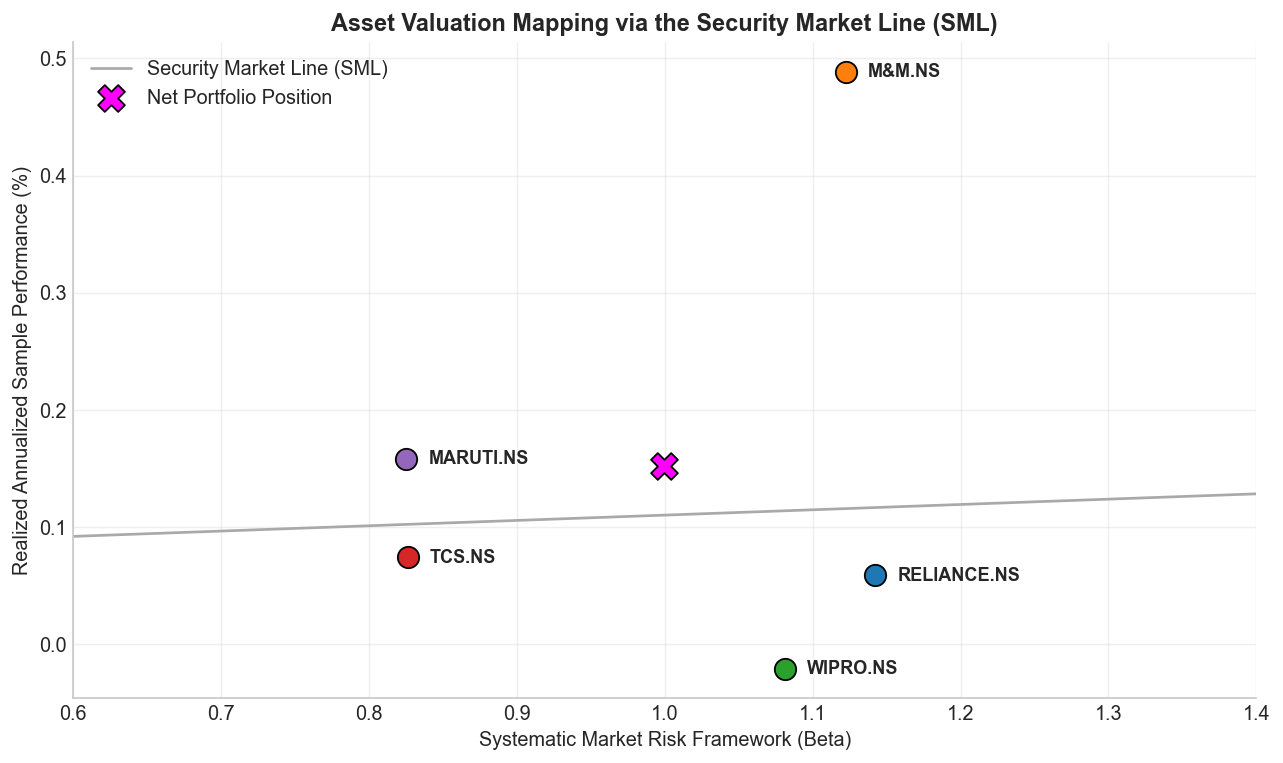

In [21]:
# 1. Cumulative Return Chart: Portfolio vs NIFTY50 (Indexed to 100 Base)
plt.figure(figsize=(12, 5.5))
indexed_portfolio = (1 + returns_df['Portfolio_Return']).cumprod() * 100
indexed_market = (1 + returns_df['NIFTY50']).cumprod() * 100

plt.plot(indexed_portfolio, label='Equal-Weight Portfolio', color='darkblue', linewidth=2)
plt.plot(indexed_market, label='NIFTY 50 Benchmark', color='orange', linewidth=1.5, linestyle='--')
plt.title("Cumulative Portfolio Growth vs Broad Market Index (Base Scale 100)", fontsize=13, fontweight='bold')
plt.xlabel("Timeline Index Date")
plt.ylabel("Capital Index Value")
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('Cumulative_Portfolio_Growth.png')
plt.show()

# 2. Security Market Line (SML) Capital Asset Pricing Plot
annualized_market_return = returns_df["NIFTY50"].mean() * 252
annualized_stock_returns = stock_returns[tickers].mean() * 252
annualized_portfolio_return = returns_df['Portfolio_Return'].mean() * 252

plt.figure(figsize=(10, 6))

# Plot the continuous SML reference baseline vector
beta_space = np.linspace(0.5, 1.5, 100)
sml_line = annual_rf + beta_space * (annualized_market_return - annual_rf)
plt.plot(beta_space, sml_line, color='darkgrey', linestyle='-', label='Security Market Line (SML)')

# Render individual asset points and annotate their ticker codes
for ticker in tickers:
    b = beta_dict[ticker]
    r = annualized_stock_returns[ticker]
    plt.scatter(b, r, s=140, zorder=5, edgecolor='black')
    plt.text(b + 0.015, r, ticker, fontsize=10, fontweight='bold', va='center')

# Render the final mixed portfolio mark position onto the frame
plt.scatter(portfolio_beta, annualized_portfolio_return, color='magenta', marker='X', s=220, zorder=6, 
            label='Net Portfolio Position', edgecolor='black')

plt.title("Asset Valuation Mapping via the Security Market Line (SML)", fontsize=13, fontweight='bold')
plt.xlabel("Systematic Market Risk Framework (Beta)")
plt.ylabel("Realized Annualized Sample Performance (%)")
plt.xlim(0.6, 1.4)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('Asset_Valuation_Mapping.png')
plt.show()

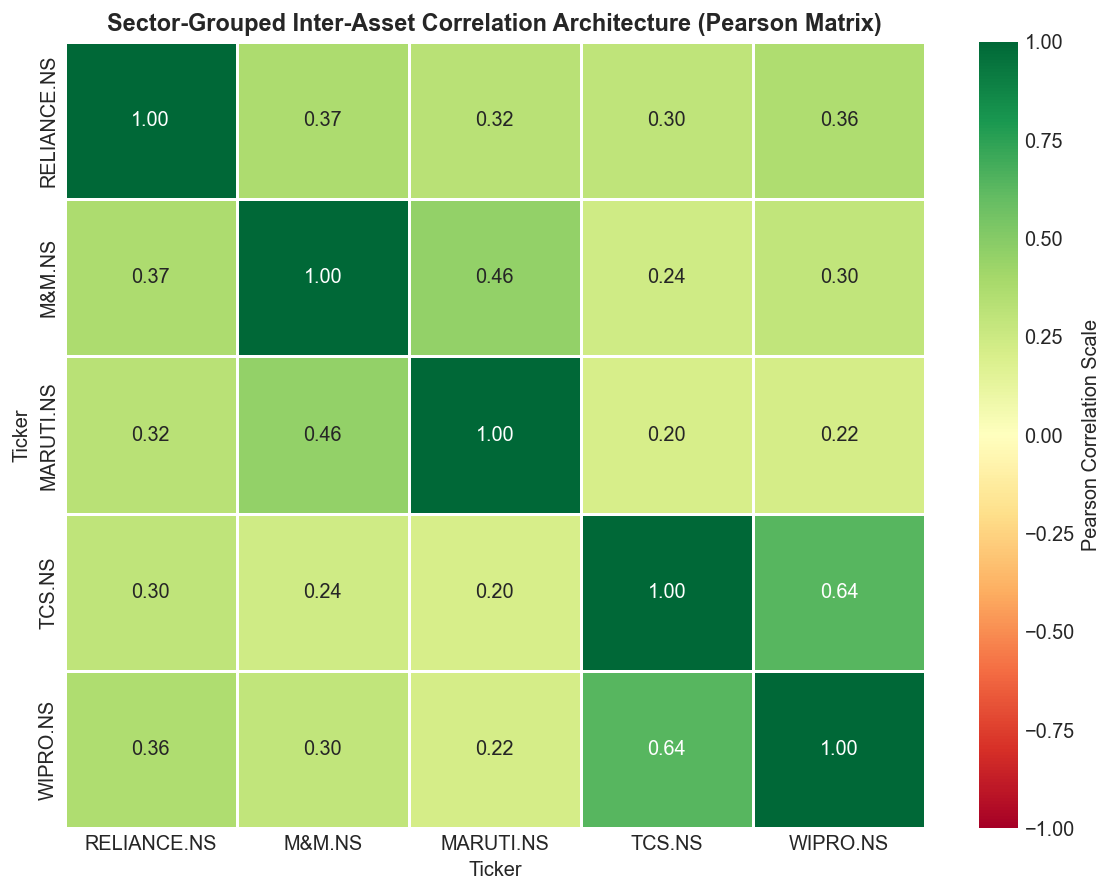

--- AUTOMATED MATRIX AUDITING LOGS ---


In [22]:
# Order rows and columns by sector cluster so intra-sector blocks are visually grouped
sector_ordered_tickers = ["RELIANCE.NS", "M&M.NS", "MARUTI.NS", "TCS.NS", "WIPRO.NS"]

# FIX: Changed 'sector_ordered_assets' to 'sector_ordered_tickers'
ordered_returns_matrix = stock_returns[sector_ordered_tickers]

# Compute Pearson Correlation DataFrame
correlation_matrix = ordered_returns_matrix.corr()

# Generate the visual color-blocked sector heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, linewidths=0.6, fmt=".2f",
            cbar_kws={'label': 'Pearson Correlation Scale'})
plt.title("Sector-Grouped Inter-Asset Correlation Architecture (Pearson Matrix)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('(Pearson_Matrix).png')
plt.show()

# Automated script reporting flags for high-risk and high-diversifier connections
print("--- AUTOMATED MATRIX AUDITING LOGS ---")
for i in range(len(sector_ordered_tickers)):
    for j in range(i + 1, len(sector_ordered_tickers)):
        val = correlation_matrix.iloc[i, j]
        t1, t2 = sector_ordered_tickers[i], sector_ordered_tickers[j]
        if val > 0.85:
            print(f"[CONCENTRATION RISK FLAG] Strong co-movement observed between {t1} and {t2}: {val:.2f}")
        elif val < 0.20:
            print(f"[DIVERSIFICATION ASSET BOND] Favorable decouple found between {t1} and {t2}: {val:.2f}")

In [23]:
# 1. Isolate an All-Automotive Double-Asset Concentration base framework
auto_subset = stock_returns[["M&M.NS", "MARUTI.NS"]]
auto_weights = np.array([0.5, 0.5])

# Calculate daily variances for both tracking sets
variance_auto_concentration = auto_subset.dot(auto_weights).var()
variance_mixed_portfolio = returns_df['Portfolio_Return'].var()

# 2. Quantify structural allocation benefit percentage reduction
variance_reduction_percentage = (1.0 - (variance_mixed_portfolio / variance_auto_concentration)) * 100

print("--- PORTFOLIO DIVERSIFICATION METRICS ---")
print(f"Daily Volatility Variance (100% Automotive Sector Concentration Frame): {variance_auto_concentration:.6f}")
print(f"Daily Volatility Variance (5-Asset Mixed-Sector Portfolio Platform) : {variance_mixed_portfolio:.6f}")
print(f"Quantifiable Structural Risk Variance Reduction Attained               : {variance_reduction_percentage:.2f}%")

--- PORTFOLIO DIVERSIFICATION METRICS ---
Daily Volatility Variance (100% Automotive Sector Concentration Frame): 0.000188
Daily Volatility Variance (5-Asset Mixed-Sector Portfolio Platform) : 0.000108
Quantifiable Structural Risk Variance Reduction Attained               : 42.61%
